# SmartPark AI Week 4 Data Quality with FYP Recordings

This run uses the FYP overhead miniature parking data the project owner authorised for this lab. It covers the next development stage: detector development, replay of occupancy and tracking behaviour, and inspection of uncertainty handling.

The private input bundle contains prepared pilot images and indexed replay frames with their source metadata. The SHA-256 printed below identifies the same input pinned by the Week 3 image-pipeline manifests. The public cleaned records use aliases and ZIP-relative image references. To run the notebook, set **SMARTPARK_FYP_INPUT_ZIP** to the private bundle path. Colab offers an upload prompt if the path is unset. Use an approved runtime for the footage. The notebook needs no model or API key.

## Part A0 Quality gate plan

| Topic 2 requirement | Evidence needed | Measurable check and decision |
|---|---|---|
| FR1 and RAI1 Occupancy and safe guidance | Usable toy-car images and aligned camera replay with known and unknown bay states | Verify file fingerprints and image decoding. Check all 24 bay IDs in each chosen frame, recognised states and abstention evidence when alignment fails. Missing critical evidence triggers review or hold. |
| FR2 and RAI2 Vehicle tracking and uncertainty | Ordered clips, synchronised positions, session-scoped track IDs and markers | Keep consecutive frames together, check timestamp linkage and finite coordinates, and preserve intervals with missing alignment. Keep independently labelled evaluation as a separate later activity. |

In [1]:
import importlib.util
import subprocess
import sys

packages = {"pandera": "pandera[pandas]==0.26.1", "pandas": "pandas>=2.1.1",
            "PIL": "Pillow", "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

## Parts A1 to A3 Verify and inspect the project hand-off

The detector pilot contributes 85 prepared images with model-assisted, visually reviewed car bounding boxes. It includes negative images and multiple crops derived from earlier source frames. Its recorded splits are useful for tracing lineage. The current review treats the entire pilot as development evidence.

Five live FYP sessions contribute four ten-frame windows each. Each window preserves the original consecutive frame indices and capture order. The camera images contain prototype overlays used for replay diagnosis. Bay states and tracks come from synchronised prototype logs. They are observations generated by the system under review.

Visual inspection of the source recordings found an alignment-loss view in **R01 frame 224** and **R04 frame 177**. **R03 frame 81** shows a readable board with cars in both bays and lanes. **R05 frame 297** shows a hand moving a car. The underlying logs can mark a bay unknown during obstructions or alignment loss. These examples support the coverage assessment without judging every log state against independent labels.

In [2]:
from collections import Counter, defaultdict
from hashlib import sha256
from io import BytesIO
from math import isclose, isfinite
from pathlib import Path, PurePosixPath
from zipfile import ZIP_DEFLATED, ZipFile
import json
import os
import pickle

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import pandera.pandas as pa
from PIL import Image

COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
if "SMARTPARK_FYP_INPUT_ZIP" in os.environ:
    input_zip = Path(os.environ["SMARTPARK_FYP_INPUT_ZIP"])
elif COLAB and Path("/content/smartpark_fyp_review_input.zip").is_file():
    input_zip = Path("/content/smartpark_fyp_review_input.zip")
elif COLAB:
    from google.colab import files

    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Choose the private SmartPark FYP review ZIP.")
    input_zip = BytesIO(next(iter(uploaded.values())))
else:
    raise ValueError("Set SMARTPARK_FYP_INPUT_ZIP to the private review ZIP path.")

output_dir = Path(os.environ.get("SMARTPARK_FYP_OUTPUT_DIR", "smartpark_fyp_week4"))
with ZipFile(input_zip) as archive:
    manifest_bytes = archive.read("manifest.json")
    manifest = json.loads(manifest_bytes)
    zip_index = Counter(archive.namelist())
if manifest["format"] != 1 or not manifest["records"]:
    raise ValueError("Expected the prepared FYP data manifest (format 1).")
records = manifest["records"]
manifest_hash = sha256(manifest_bytes).hexdigest()
record_counts = Counter(row["record_id"] for row in records)
path_counts = Counter(row["image_path"] for row in records)
print(f"Prepared hand-off: {len(records)} records.")
print(f"Manifest SHA-256: {manifest_hash}")

Prepared hand-off: 285 records.
Manifest SHA-256: 11b270f4d4fb7c97cb81463505881cab037f497c514ad2a2f0e2a3af95d83612


## Parts A4 and A5 Validate and triage

Pandera checks each record against the image and metadata contract. A failure quarantines that record. The summary preserves the rule, its rationale, the measured failures and the decision. Valid exceptions remain visible in the coverage review. These include labelled empty images and unknown bay states.

In [3]:
EXPECTED_BAYS = {f"P{i:02d}" for i in range(1, 25)}
STATES = {"occupied", "vacant", "unknown"}
KNOWN_KINDS = {"annotated_replay", "detector_image"}

RULES = {
    "identity": ("The record ID and private image path are unique and the declared source/type are present.",
                 "Prevents ambiguous lineage or counting the same index row twice."),
    "integrity": ("The original SHA-256 matches, and the image verifies and decodes as RGB JPEG.",
                  "Detects missing, corrupt, substituted or incorrectly encoded images."),
    "detector_annotations": ("Car class 0 boxes match the count and have finite coordinates within the image.",
                             "Detects malformed labels. Reviewed negatives can legitimately have zero boxes."),
    "bay_coverage": ("For replay, all 24 distinct bay IDs have a recognised state and a reason.",
                     "Prevents missing or invented statuses and preserves the reason for uncertainty."),
    "replay_sync": ("For replay, frame time agrees with each bay state and track within 0.1 ms.",
                     "Prevents joining the wrong moment of a clip with a bay status or vehicle position."),
    "track_schema": ("For replay, track IDs in each frame are distinct and coordinates are finite.",
                     "Detects records that cannot be replayed or traced to a unique track."),
    "alignment_abstention": ("Frames with invalid alignment report all 24 bays as unknown.",
                             "Detects cases where unusable alignment could be presented as a known bay state."),
}

def detector_box_ok(box):
    if len(box) != 5 or not all(isfinite(value) for value in box):
        return False
    label, x, y, w, h = box
    # The archive rounds its normalised YOLO coordinates to eight decimal places.
    tolerance = 1e-6
    return (label == 0 and w > 0 and h > 0
            and min(x - w / 2, y - h / 2) >= -tolerance
            and max(x + w / 2, y + h / 2) <= 1 + tolerance)

def audit_record(archive, row):
    image_path = row["image_path"]
    parts = PurePosixPath(image_path).parts
    image_present = bool(parts and parts[0] == "images" and ".." not in parts
                         and zip_index[image_path] == 1)
    identity = (image_present and record_counts[row["record_id"]] == 1
                and path_counts[image_path] == 1
                and bool(row["source_id"] and row["source_version"] and row["annotation_origin"])
                and row["kind"] in KNOWN_KINDS)
    byte_hash = pixel_hash = image_error = ""
    dimensions = ()
    integrity = False
    if image_present:
        try:
            payload = archive.read(image_path)
            byte_hash = sha256(payload).hexdigest()
            with Image.open(BytesIO(payload)) as im:
                integrity = im.format == "JPEG" and im.mode == "RGB" and byte_hash == row["sha256"]
                im.verify()
            with Image.open(BytesIO(payload)) as im:
                im.load()
                dimensions = im.size
                pixel_hash = sha256(repr(im.size).encode() + im.tobytes()).hexdigest()
        except (OSError, ValueError, SyntaxError) as exc:
            integrity = False
            image_error = str(exc)
    else:
        image_error = "Expected exactly one image at the manifest path"

    annotations = bay_coverage = replay_sync = track_schema = alignment_abstention = True
    if row["kind"] == "detector_image":
        boxes = row["boxes"]
        annotations = (len(boxes) == row["box_count"] and all(map(detector_box_ok, boxes))
                       and (bool(boxes) or "negative" in row["image_kind"]))
    else:
        bays, tracks = row["bay_states"], row["tracks"]
        bay_coverage = (len(bays) == len(EXPECTED_BAYS)
                        and {bay["bay"] for bay in bays} == EXPECTED_BAYS
                        and all(bay["state"] in STATES and bay["reason"] for bay in bays))
        replay_sync = (isfinite(row["seconds"]) and row["seconds"] >= 0
                       and all(isclose(row["seconds"], entry["seconds"], abs_tol=0.0001, rel_tol=0)
                               for entry in bays + tracks))
        track_schema = (len({track["track_id"] for track in tracks}) == len(tracks)
                        and all(track["track_id"].isdigit() and isfinite(track["x_mm_proxy"])
                                and isfinite(track["y_mm_proxy"]) for track in tracks))
        alignment_abstention = row["aligned"] or all(bay["state"] == "unknown" for bay in bays)

    return dict(identity=identity, integrity=integrity, detector_annotations=annotations,
                bay_coverage=bay_coverage, replay_sync=replay_sync, track_schema=track_schema,
                alignment_abstention=alignment_abstention, observed_sha256=byte_hash,
                pixel_sha256=pixel_hash, dimensions=dimensions, image_error=image_error)

with ZipFile(input_zip) as archive:
    images = [audit_record(archive, record) for record in records]
profile = pd.DataFrame(images)
schema = pa.DataFrameSchema({
    key: pa.Column(bool, pa.Check(lambda field: field, error=key), nullable=False) for key in RULES
})
try:
    schema.validate(profile[list(RULES)], lazy=True)
    pandera_failures = []
except pa.errors.SchemaErrors as exc:
    if exc.failure_cases["index"].isna().any():
        raise RuntimeError("Unexpected Pandera schema failure") from exc
    pandera_failures = exc.failure_cases[["column", "index"]].to_dict("records")

failure_rows = [{
    "record_id": records[item["index"]]["record_id"], "rule": item["column"],
    "condition": RULES[item["column"]][0], "why": RULES[item["column"]][1],
    "decision": "Quarantine", "image_error": images[item["index"]]["image_error"],
} for item in pandera_failures]
rejected = {item["index"] for item in pandera_failures}
failure_counts = Counter(row["rule"] for row in failure_rows)
rule_summary = [
    {"Rule": key, "Condition": condition, "Why this rule?": reason,
     "Failures": failure_counts[key], "Decision": "Quarantine on failure"}
    for key, (condition, reason) in RULES.items()
]
display(pd.DataFrame(rule_summary))
print(f"{len(failure_rows)} rule flags and {len(rejected)} quarantined records.")

Rule,Condition,Why this rule?,Failures,Decision
identity,The record ID and private image path are unique and the declared source/type are present.,Prevents ambiguous lineage or counting the same index row twice.,0,Quarantine on failure
integrity,"The original SHA-256 matches, and the image verifies and decodes as RGB JPEG.","Detects missing, corrupt, substituted or incorrectly encoded images.",0,Quarantine on failure
detector_annotations,Car class 0 boxes match the count and have finite coordinates within the image.,Detects malformed labels. Reviewed negatives can legitimately have zero boxes.,0,Quarantine on failure
bay_coverage,"For replay, all 24 distinct bay IDs have a recognised state and a reason.",Prevents missing or invented statuses and preserves the reason for uncertainty.,0,Quarantine on failure
replay_sync,"For replay, frame time agrees with each bay state and track within 0.1 ms.",Prevents joining the wrong moment of a clip with a bay status or vehicle position.,0,Quarantine on failure
track_schema,"For replay, track IDs in each frame are distinct and coordinates are finite.",Detects records that cannot be replayed or traced to a unique track.,0,Quarantine on failure
alignment_abstention,Frames with invalid alignment report all 24 bays as unknown.,Detects cases where unusable alignment could be presented as a known bay state.,0,Quarantine on failure


0 rule flags and 0 quarantined records.


## Parts B1 to B4 Deduplication, coverage, bias and governance

- Exact SHA-256 and decoded-pixel checks find identical content. Verified replay frames retain their original temporal metadata and are grouped by recording session. Detector crops keep their source IDs and base-frame IDs for split checks.
- The preparation uses one miniature board and limited lighting and equipment. Capture changes, small roof markers and temporary hand obstruction can alter visibility. Inspect each of these conditions before trusting similar outputs in a new session.
- A model-assisted car box can miss an object under occlusion. Bay and track logs inherit the prototype's assumptions about alignment, dwell time and position. Keep overlays out of detector training, withhold unsupported guidance and prepare independent ground truth before formal scoring.
- The FYP images are used for this lab and controlled development. Source dates in replay metadata are recording dates. Deterministic hashes identify the review snapshot. The public project files include the pseudonymous cleaned metadata. The image and source mapping files stay in the private bundle.

In [4]:
dedup_rows = []
unique = {}
for i, (record, observation) in enumerate(zip(records, images)):
    if i in rejected:
        continue
    pixel_hash = observation["pixel_sha256"]
    if pixel_hash in unique:
        first = unique[pixel_hash]
        same_bytes = first["sha256"] == record["sha256"]
        dedup_rows.append({"kept_record": first["record_id"], "duplicate_record": record["record_id"],
                           "same_file_bytes": same_bytes, "pixel_sha256": pixel_hash})
        first["additional_provenance"].append({
            "record_id": record["record_id"], "source_id": record["source_id"],
            "image_path": record["image_path"], "sha256": record["sha256"],
        })
        continue
    unique[pixel_hash] = {**record, "additional_provenance": [], "review_manifest_sha256": manifest_hash}
clean = list(unique.values())
replay = [r for r in clean if r["kind"] == "annotated_replay"]
detector = [r for r in clean if r["kind"] == "detector_image"]
state_counts = Counter(b["state"] for r in replay for b in r["bay_states"])
bay_ids = {b["bay"] for r in replay for b in r["bay_states"]}
issue_counts = Counter(b["parking_issue"] for r in replay for b in r["bay_states"] if b["parking_issue"])
source_counts = Counter(r["source_id"] for r in clean)
pilot_split_counts = Counter(r["original_split"] for r in detector)
source_splits = defaultdict(set)
for r in detector:
    source_splits[r["source_id"]].add(r["original_split"])
cross_split_sources = sorted(source for source, splits in source_splits.items() if len(splits) > 1)
windows = defaultdict(list)
for row in replay:
    windows[(row["source_id"], row["window"])].append((row["frame"], row["seconds"]))
complete_windows = 0
for positions in windows.values():
    sequence = sorted(positions)
    indices = [i for i, _ in sequence]
    times = [seconds for _, seconds in sequence]
    complete_windows += (len(indices) == 10 and indices == list(range(indices[0], indices[0] + 10))
                         and all(t2 > t1 for t1, t2 in zip(times, times[1:])))

facts = {
    "input": len(records), "clean": len(clean), "rejected": len(rejected),
    "duplicates": len(dedup_rows), "detector_images": len(detector), "replay_frames": len(replay),
    "replay_sessions": len({r["source_id"] for r in replay}),
    "capture_dates": sorted({r["capture_date"] for r in replay}),
    "bay_count": len(bay_ids), "bay_observations": sum(state_counts.values()),
    "bay_states": dict(state_counts), "by_source": dict(source_counts),
    "complete_windows": complete_windows, "windows": len(windows),
    "bay_issues": dict(issue_counts), "frames_with_tracks": sum(bool(r["tracks"]) for r in replay),
    "track_observations": sum(len(r["tracks"]) for r in replay),
    "alignment_loss_frames": sum(not r["aligned"] for r in replay),
    "detector_boxes": sum(len(r["boxes"]) for r in detector),
    "negative_images": sum(not r["boxes"] for r in detector),
    "original_detector_splits": dict(pilot_split_counts), "cross_split_sources": cross_split_sources,
}
coverage_met = (
    bay_ids == EXPECTED_BAYS and state_counts.keys() == STATES
    and complete_windows == len(windows) and len(windows) > 0 and facts["replay_sessions"] >= 2
    and facts["frames_with_tracks"] > 0 and facts["alignment_loss_frames"] > 0
    and facts["detector_boxes"] > 0 and facts["negative_images"] > 0 and not cross_split_sources
)
facts["development_gate"] = "GO" if coverage_met and not rejected else "HOLD"
print(json.dumps(facts, indent=2))

{
  "input": 285,
  "clean": 285,
  "rejected": 0,
  "duplicates": 0,
  "detector_images": 85,
  "replay_frames": 200,
  "replay_sessions": 5,
  "capture_dates": [
    "2026-11-19",
    "2026-11-20",
    "2026-11-21"
  ],
  "bay_count": 24,
  "bay_observations": 4800,
  "bay_states": {
    "unknown": 1972,
    "vacant": 1608,
    "occupied": 1220
  },
  "by_source": {
    "D03": 12,
    "D04": 63,
    "D01": 2,
    "D05": 3,
    "D02": 5,
    "R01": 40,
    "R02": 40,
    "R03": 40,
    "R04": 40,
    "R05": 40
  },
  "complete_windows": 20,
  "windows": 20,
  "bay_issues": {
    "straddling": 232,
    "over_line": 161,
    "shared_bay": 67,
    "unverified": 3
  },
  "frames_with_tracks": 170,
  "track_observations": 2977,
  "alignment_loss_frames": 23,
  "detector_boxes": 573,
  "negative_images": 9,
  "original_detector_splits": {
    "train": 80,
    "val": 2,
    "test": 3
  },
  "cross_split_sources": [],
  "development_gate": "GO"
}


## Part C Export the reviewed data and record the gate

The cleaned JSONL and trusted local pickle contain equivalent records. Image paths are relative to the approved private input bundle. The coverage plot and CSVs are submission evidence. The gate concerns fitness for the stated development use. Formal accuracy, tracking scores and guidance safety tests need independent labels and fresh held-out recordings.

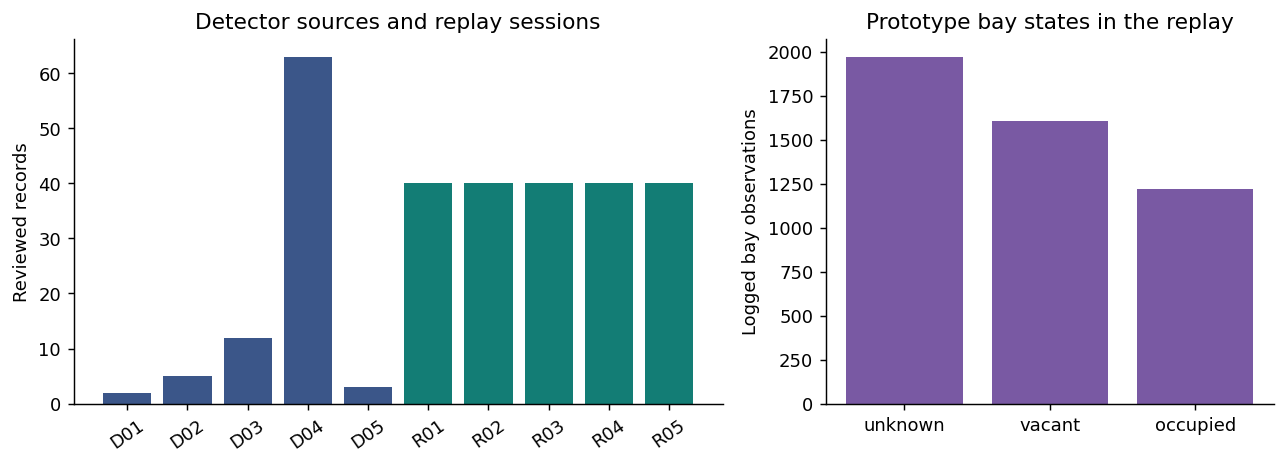

JSONL and pickle round-trip verified: 285 records in each.
Topic 4 gate for offline SmartPark development: GO.
Evidence ZIP: week4_fyp_evidence_evidence.zip


In [5]:
out_data, out_docs = output_dir / "data", output_dir / "docs"
out_data.mkdir(parents=True, exist_ok=True)
out_docs.mkdir(parents=True, exist_ok=True)
pd.DataFrame(failure_rows, columns=["record_id", "rule", "condition", "why", "decision", "image_error"]).to_csv(
    out_docs / "week4_validation_failures.csv", index=False, lineterminator="\n")
pd.DataFrame(dedup_rows, columns=["kept_record", "duplicate_record", "same_file_bytes", "pixel_sha256"]).to_csv(
    out_docs / "week4_duplicate_review.csv", index=False, lineterminator="\n")
pd.DataFrame(rule_summary).to_csv(out_docs / "week4_validation_summary.csv", index=False, lineterminator="\n")
(out_docs / "week4_fyp_review_summary.json").write_text(json.dumps(facts, indent=2) + "\n", encoding="utf-8")

with plt.ioff():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), gridspec_kw={"width_ratios": [1.45, 1]})
for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
for source, value in sorted(source_counts.items()):
    axes[0].bar(source, value, color="#137d75" if source.startswith("R") else "#3b5689")
axes[0].tick_params(axis="x", rotation=35)
axes[0].set_ylabel("Reviewed records")
axes[0].set_title("Detector sources and replay sessions")
axes[1].bar(list(state_counts), list(state_counts.values()), color="#7959a3")
axes[1].set_ylabel("Logged bay observations")
axes[1].set_title("Prototype bay states in the replay")
fig.tight_layout()
plot_path = out_docs / "week4_coverage_by_source.png"
fig.savefig(plot_path, dpi=130, bbox_inches="tight")
plt.close(fig)
with Image.open(plot_path) as plot:
    display(plot.copy())

jsonl_path = out_data / "prepared_chunks_clean.jsonl"
pkl_path = out_data / "chunks_clean.pkl"
with jsonl_path.open("w", encoding="utf-8", newline="\n") as file:
    for row in clean:
        file.write(json.dumps(row, allow_nan=False) + "\n")
with pkl_path.open("wb") as file:
    pickle.dump(clean, file, protocol=4)
reloaded_json = [json.loads(line) for line in jsonl_path.read_text(encoding="utf-8").splitlines()]
with pkl_path.open("rb") as file:
    reloaded_pickle = pickle.load(file)  # This file was written by this notebook.
assert reloaded_json == reloaded_pickle == clean
assert all(zip_index[row["image_path"]] == 1 for row in reloaded_json)
print(f"JSONL and pickle round-trip verified: {len(clean)} records in each.")
print(f"Topic 4 gate for offline SmartPark development: {facts['development_gate']}.")

archive_path = output_dir.with_name(output_dir.name + "_evidence.zip")
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as evidence:
    for subdir in (out_data, out_docs):
        for path in sorted(subdir.iterdir()):
            if path.is_file():
                evidence.write(path, path.relative_to(output_dir).as_posix())
print(f"Evidence ZIP: {archive_path.name}")

In [6]:
if COLAB:
    from google.colab import files

    files.download(str(archive_path))